# Klinokinesis and klinotaxis

*C. elegans* climbs a chemical gradient with two strategies:

- **Klinokinesis** (pirouettes): reverse and turn more often when the
  concentration is **falling**, run straight when it is rising. It uses only
  the change over time, so it needs no sense of direction.
- **Klinotaxis** (weathervaning): curve gradually toward the side where the
  concentration is **higher**. The worm gets that side information from its
  head sweeping left and right.

For a repellent such as a toxin both are reversed: reverse when the
concentration rises, steer toward the side where it is lower.

Each test below isolates one behaviour by controlling the geometry. The worm
cruises straight, then a single source is placed at a fixed bearing and the
deterministic policy takes over. Eating is disabled, so the source stays put.

**Point `CHECKPOINT` at a checkpoint and run all.**

In [1]:
# ── point this at a checkpoint ───────────────────────────────────────────────
CHECKPOINT = "experiments/head_sweep_v7_s0/checkpoints/epoch_01000.pt"
HEADINGS = 24   # starting headings per condition; more gives tighter intervals, slower

In [2]:
import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Resolve paths against the repo root, so the notebook works whether it is run
# from the project root or from notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ppo import load_policy

# Randomisation off, so every trial sees the same body and the only thing that
# varies between repeats is the starting heading and head-sweep phase.
FIXED = {"randomization": {"enabled": False}}
ac, env_sweep, state = load_policy(ROOT / CHECKPOINT, env_overrides=FIXED)
# The control: the same policy with the sweep shrunk to nothing. The phase
# channels still tick, but the head no longer moves, so smell carries no side
# information. (Amplitude 0 is rejected while the phase channels are on.)
_, env_still, _ = load_policy(
    ROOT / CHECKPOINT, env_overrides={**FIXED, "worm": {"head_sweep_amplitude": 1e-6}}
)
print(f"{CHECKPOINT}  (epoch {state['epoch']})")

INK, INK_SOFT, GRID_C = "#0b0b0b", "#52514e", "#e3e2df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
FOOD_C, TOXIN_C = "#1baf7a", "#d64545"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID_C, "axes.labelcolor": INK_SOFT, "text.color": INK,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "figure.dpi": 110, "legend.fontsize": 7,
})

experiments/head_sweep_v7_s0/checkpoints/epoch_01000.pt  (epoch 1000)


In [3]:
WARM, CRUISE = 4, 0.6          # straight cruise before the policy takes over
CENTRE = np.array([10.0, 10.0])  # far enough from every wall for 25 steps
LEFT, RIGHT, AHEAD, BEHIND = np.pi / 2, -np.pi / 2, 0.0, np.pi


def unit(angle):
    return np.array([np.cos(angle), np.sin(angle)])


def trial(env, kind, bearing, dist, heading, seed, steps):
    """Runs the policy from a controlled start.

    The worm cruises straight for WARM steps, so the frame stack already holds
    a real rise or fall, then the deterministic policy acts for `steps` steps.
    The source is placed relative to where the body is when the policy starts.

    Args:
        env: Environment from load_policy.
        kind: "food" or "toxin".
        bearing: Source direction relative to the heading (positive is left),
            or None for no source.
        dist: Source distance from the body when the policy starts.
        heading: Starting heading in the world.
        seed: Reset seed. Conditions sharing a seed share the head-sweep phase.
        steps: Policy steps to run.

    Returns:
        A dict with the actions taken, the body path in the worm's starting
        frame (x forward, y to the left) and the source in that frame.
    """
    world = env.unwrapped
    obs, _ = env.reset(seed=seed)
    world.worm.position, world.worm.heading = CENTRE.copy(), heading
    world.food.positions = np.zeros((0, 2))
    world.toxin.positions = np.zeros((0, 2))
    world.food.consume = lambda *a, **k: 0
    world.metabolism.energy = 0.6 * world.config.metabolism.max_energy

    start = CENTRE + WARM * CRUISE * world.worm.max_speed * world.config.world.dt * unit(heading)
    source = None if bearing is None else start + dist * unit(heading + bearing)
    if source is not None:
        getattr(world, kind).positions = source[None]
    for _ in range(WARM):
        obs, *_ = env.step(np.array([0.0, CRUISE]))
    assert np.allclose(world.worm.position, start), "the source was placed off target"

    frame = np.array([unit(heading), unit(heading + np.pi / 2)])  # rows: forward, left
    path, actions = [frame @ (world.worm.position - start)], []
    for _ in range(steps):
        action = np.clip(ac.act(torch.as_tensor(obs, dtype=torch.float32), deterministic=True), -1, 1)
        obs, *_ = env.step(action)
        actions.append(action)
        path.append(frame @ (world.worm.position - start))
    return {
        "actions": np.array(actions),
        "path": np.array(path),
        "source": None if source is None else frame @ (source - start),
    }


def condition(env, kind, bearing, dists, steps):
    """Runs one trial per (heading, distance). Trial i always uses seed i."""
    headings = np.linspace(-np.pi, np.pi, HEADINGS, endpoint=False)
    grid = itertools.product(headings, dists)
    return [trial(env, kind, bearing, d, h, i, steps) for i, (h, d) in enumerate(grid)]


def mean_ci(x):
    """Mean and 95% confidence half-width."""
    x = np.asarray(x, dtype=float)
    return x.mean(), 1.96 * x.std(ddof=1) / np.sqrt(len(x))

## 1. Where the side information comes from

The worm smells at a single point, its head. Holding the body still and
letting the head sweep shows what one sensor can learn: with food on the left
the smell peaks when the head swings left (phase +90°), and with food on the
right it peaks half a cycle later.

So the smell's change multiplied by `cos(phase)` averages **positive** for food
on the left and **negative** for food on the right. The policy sees both the
smell change and the phase in one observation, so it can compute this product.
No policy is involved in this cell; it is the environment alone.

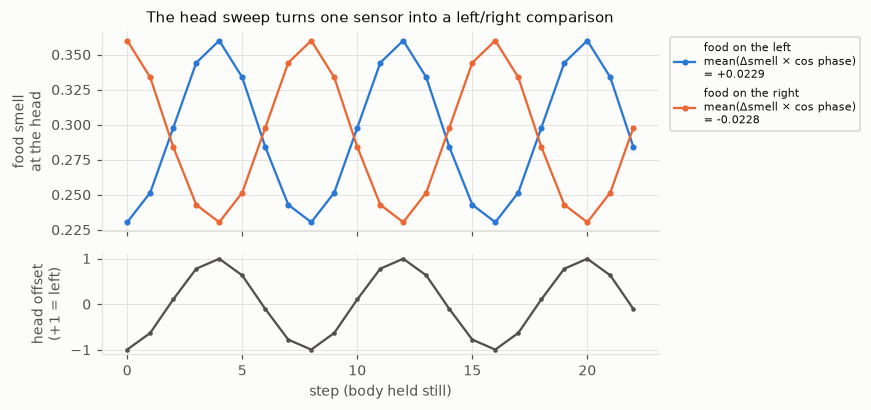

In [4]:
def still_head(side):
    world = env_sweep.unwrapped
    env_sweep.reset(seed=0)
    world.worm.position, world.worm.heading = CENTRE.copy(), 0.0
    world.toxin.positions = np.zeros((0, 2))
    world.food.positions = (CENTRE + 2.2 * unit(side))[None]
    rows = []
    for _ in range(24):  # three sweep cycles
        _, _, _, _, info = env_sweep.step(np.zeros(2))
        rows.append((world.worm.phase, info["food_smell"]))
    phase, smell = np.array(rows).T
    delta = np.diff(smell)
    return phase[1:], smell[1:], np.mean(delta * np.cos(phase[1:]))


fig, (ax, head_ax) = plt.subplots(2, 1, figsize=(8, 3.8), sharex=True,
                                  gridspec_kw={"height_ratios": [2, 1]})
for side, name, colour in ((LEFT, "food on the left", SERIES[0]), (RIGHT, "food on the right", SERIES[1])):
    phase, smell, side_signal = still_head(side)
    ax.plot(smell, color=colour, marker="o", ms=3,
            label=f"{name}\nmean(Δsmell × cos phase)\n= {side_signal:+.4f}")
head_ax.plot(np.sin(phase), color=INK_SOFT, marker="o", ms=2)
ax.set(ylabel="food smell\nat the head",
       title="The head sweep turns one sensor into a left/right comparison")
head_ax.set(ylabel="head offset\n(+1 = left)", xlabel="step (body held still)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout();

## 2. Klinotaxis: steering toward the side with more food

A source is placed exactly beside the worm, at +90° (left) or −90° (right).
At that bearing the concentration is not yet rising or falling as the worm
moves forward, so the only way to choose a turning direction is side
information from the sweep.

- **Steering index**: mean turn command with the source on the left, minus
  with it on the right. Positive means it turns toward the source.
- **Sidestep**: how far the body actually moved toward the source's side,
  averaged over left and right. A habit of always turning one way cancels, and
  it measures real movement, so reversing (which moves the body backward along
  the heading) cannot flip its sign.

The control repeats everything with the sweep switched off. Klinotaxis is the
part of the sidestep that disappears without the sweep. What remains comes
from klinokinesis, which also moves a worm down or up a gradient over time.

steering L-R sidestep toward (units)
source sweep                                        
food   on     +0.511 ± 0.021            +1.76 ± 0.08
       off    +0.064 ± 0.042            +0.39 ± 0.21
toxin  on     -0.233 ± 0.037            -1.04 ± 0.17
       off    +0.206 ± 0.056            -0.73 ± 0.12

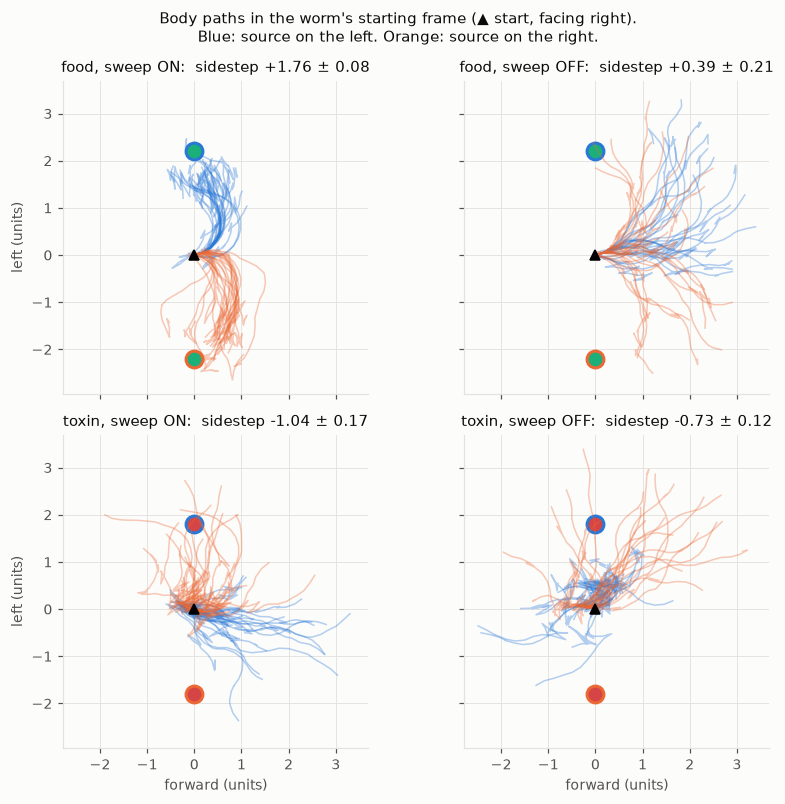

In [5]:
TAXIS_STEPS = 25
TAXIS_DISTS = {"food": [1.8, 2.2, 2.6], "toxin": [1.4, 1.8, 2.2]}

taxis = {
    (kind, sweep): {side: condition(env, kind, bearing, TAXIS_DISTS[kind], TAXIS_STEPS)
                    for side, bearing in (("left", LEFT), ("right", RIGHT))}
    for kind in ("food", "toxin")
    for sweep, env in (("on", env_sweep), ("off", env_still))
}


def steering(runs):
    return [l["actions"][:, 0].mean() - r["actions"][:, 0].mean() for l, r in zip(runs["left"], runs["right"])]


def sidestep(runs):
    return [(l["path"][-1, 1] - r["path"][-1, 1]) / 2 for l, r in zip(runs["left"], runs["right"])]


fig, axes = plt.subplots(2, 2, figsize=(8, 7.4), sharex=True, sharey=True)
for row, kind in enumerate(("food", "toxin")):
    for col, sweep in enumerate(("on", "off")):
        ax, runs = axes[row, col], taxis[(kind, sweep)]
        for side, colour in (("left", SERIES[0]), ("right", SERIES[1])):
            # The middle distance only, so each panel shows one source per side.
            shown = [t for t in runs[side] if np.isclose(np.linalg.norm(t["source"]), TAXIS_DISTS[kind][1])]
            for t in shown:
                ax.plot(*t["path"].T, color=colour, alpha=0.35, lw=1)
            ax.plot(*shown[0]["source"], "o", ms=11, color=FOOD_C if kind == "food" else TOXIN_C,
                    mec=colour, mew=2)
        ax.plot(0, 0, "k^", ms=7)
        s, ci = mean_ci(sidestep(runs))
        ax.set_title(f"{kind}, sweep {sweep.upper()}:  sidestep {s:+.2f} ± {ci:.2f}")
        ax.set_aspect("equal")
for ax in axes[1]:
    ax.set_xlabel("forward (units)")
for ax in axes[:, 0]:
    ax.set_ylabel("left (units)")
fig.suptitle("Body paths in the worm's starting frame (▲ start, facing right).\n"
             "Blue: source on the left. Orange: source on the right.", fontsize=10)
fig.tight_layout()

taxis_table = pd.DataFrame([
    {"source": kind, "sweep": sweep,
     "steering L-R": "{:+.3f} ± {:.3f}".format(*mean_ci(steering(taxis[(kind, sweep)]))),
     "sidestep toward (units)": "{:+.2f} ± {:.2f}".format(*mean_ci(sidestep(taxis[(kind, sweep)])))}
    for kind, sweep in taxis
]).set_index(["source", "sweep"])
taxis_table

## 3. Klinokinesis: reversing when things get worse

The source is placed straight ahead (concentration **rising** as the worm
moves) or straight behind (**falling**), at the same distance when the policy
starts. At 0° and 180° the sweep carries no side information, so any
difference between the two is a response to the rise or fall alone. A third
condition has no source at all, as a baseline.

The window is 8 steps, one sweep cycle, which is too short to reach the
source. Reversing (negative throttle) is the measure: a pirouette starts with a
reversal.

Expected if klinokinesis is present:
- **food**: reverse more when behind (falling) than ahead (rising)
- **toxin**: reverse more when ahead (rising) than behind (falling)

reversing throttle
source position                        
food   ahead     0.068 ± 0.024    +0.80
       none      0.123 ± 0.031    +0.68
       behind    0.191 ± 0.030    +0.56
toxin  ahead     0.453 ± 0.028    +0.08
       none      0.123 ± 0.031    +0.68
       behind    0.163 ± 0.040    +0.66

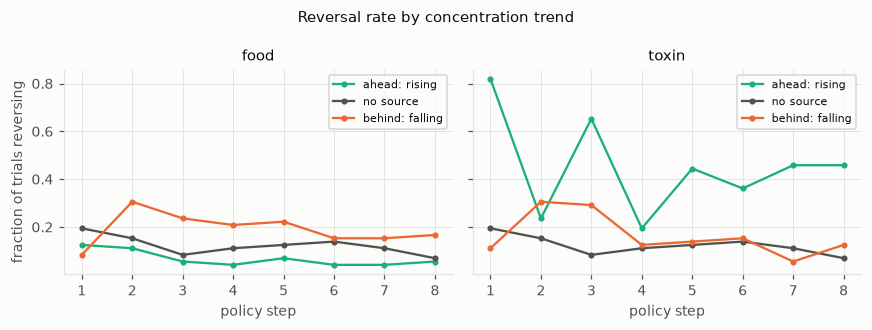

In [6]:
KIN_STEPS = 8
KIN_DISTS = {"food": [2.8, 3.2, 3.6], "toxin": [2.0, 2.4, 2.8]}

kinesis = {
    kind: {name: condition(env_sweep, kind, bearing, KIN_DISTS[kind], KIN_STEPS)
           for name, bearing in (("ahead", AHEAD), ("none", None), ("behind", BEHIND))}
    for kind in ("food", "toxin")
}


def reversing(runs):
    """Fraction of steps with negative throttle, per trial."""
    return [np.mean(t["actions"][:, 1] < 0) for t in runs]


fig, axes = plt.subplots(1, 2, figsize=(8, 3.0), sharey=True)
for ax, kind in zip(axes, ("food", "toxin")):
    for name, colour, label in (("ahead", SERIES[2], "ahead: rising"), ("none", INK_SOFT, "no source"),
                                ("behind", SERIES[1], "behind: falling")):
        per_step = np.mean([t["actions"][:, 1] < 0 for t in kinesis[kind][name]], axis=0)
        ax.plot(np.arange(1, KIN_STEPS + 1), per_step, marker="o", ms=3, color=colour, label=label)
    ax.set(title=f"{kind}", xlabel="policy step")
    ax.legend()
axes[0].set_ylabel("fraction of trials reversing")
fig.suptitle("Reversal rate by concentration trend", fontsize=10)
fig.tight_layout()

rows = []
for kind in ("food", "toxin"):
    for name in ("ahead", "none", "behind"):
        runs = kinesis[kind][name]
        rows.append({"source": kind, "position": name,
                     "reversing": "{:.3f} ± {:.3f}".format(*mean_ci(reversing(runs))),
                     "throttle": "{:+.2f}".format(np.mean([t["actions"][:, 1].mean() for t in runs]))})
pd.DataFrame(rows).set_index(["source", "position"])

## 4. Verdict

A behaviour counts as present when its 95% interval excludes zero in the
direction the biology predicts. Pairs share seeds, so each difference is taken
trial by trial.

- **klinokinesis**: reversal rate when the concentration gets worse minus when
  it gets better.
- **klinotaxis**: the sidestep that the sweep adds, sweep on minus sweep off,
  signed so that toward food and away from toxin are positive.

In [7]:
def paired(a, b):
    return mean_ci(np.subtract(a, b))


tests = {
    "food klinokinesis": paired(reversing(kinesis["food"]["behind"]), reversing(kinesis["food"]["ahead"])),
    "toxin klinokinesis": paired(reversing(kinesis["toxin"]["ahead"]), reversing(kinesis["toxin"]["behind"])),
    "food klinotaxis": paired(sidestep(taxis[("food", "on")]), sidestep(taxis[("food", "off")])),
    "toxin klinotaxis": paired(np.negative(sidestep(taxis[("toxin", "on")])),
                               np.negative(sidestep(taxis[("toxin", "off")]))),
}
pd.DataFrame([
    {"behaviour": name, "effect": f"{m:+.3f} ± {ci:.3f}", "present": "yes" if m - ci > 0 else "no"}
    for name, (m, ci) in tests.items()
]).set_index("behaviour")

,effect,present
behaviour,,
food klinokinesis,+0.123 ± 0.033,yes
toxin klinokinesis,+0.290 ± 0.051,yes
food klinotaxis,+1.375 ± 0.225,yes
toxin klinotaxis,+0.317 ± 0.180,yes
